### Imports

In [112]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import clear_output

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC

from qiskit.circuit.library import zz_feature_map
from qiskit.circuit.library import real_amplitudes
from qiskit.circuit.library import efficient_su2

from qiskit.primitives import StatevectorSampler

from qiskit_machine_learning.algorithms.classifiers import VQC
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

SEED = 123
np.random.seed(SEED)
algorithm_globals.random_seed = SEED

### Part I - Exploring the dataset

In [129]:
iris_data = load_iris()

print(iris_data.keys())
print(iris_data["feature_names"])
print(iris_data["target"])

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


**1. What does one sample represent?**

It represent an iris flower and all its features.

**2. What are the four measured features?**

'sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)'

**3. Is the dataset balanced?**

The dataset is balanced, there are exactly 50 samples per class.

**4. Is the classification problem binary or multiclass?**

It's multiclass, there are 3 classes.

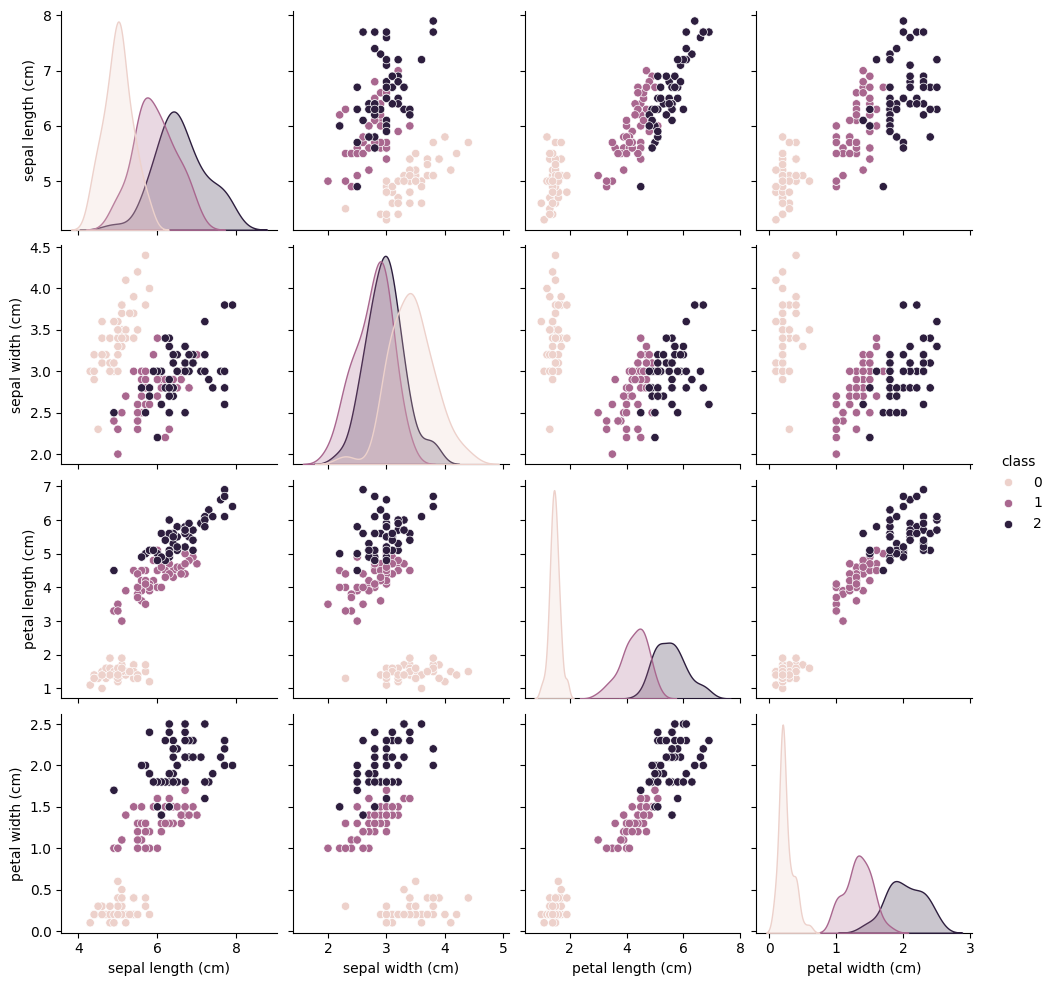

In [130]:
df = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)
df["class"] = pd.Series(iris_data.target)

sns.pairplot(df, hue="class")

### Part II - Preparing the Data

In [143]:
features = MinMaxScaler().fit_transform(df.drop(["class"], axis=1))

**1. Why is normalization useful for a machine-learning model ?**

It is easier to process and it gives better results.

**2. Why is it particularly relevant when the features are subsequently encoded into a quantum circuit ?**

Normalization is important for quantum circuit because it ensures that the state vector is normalized.

**3. What could be problematic about directly using the original feature as angles for rotation gates ?**

If we don't normalize the feature and we use directly its value as an angle, the problem is that the rotation is 2pi-periodic, so different feature values could lead to the same state vector. We don't want that.

In [144]:
train_features, test_features, train_labels, test_labels = train_test_split(features, df["class"], train_size=0.80, random_state=SEED)

print(train_features.shape)
print(train_labels.shape)
print("======================")
print(test_features.shape)
print(test_labels.shape)

(120, 4)
(120,)
(30, 4)
(30,)


**1. Why should the test set not be used during training ?**

When we test the model, we don't want that the test samples to have been known and train by the model. It must be a new sample. Otherwise it's not a prediction but a "copy" of the training.

**2. What does a high training accuracy combined with a significantly lower test accuracy indicate ?**

It means that the model overfitted. The model didn't generalize and only learned "by heart" the given training samples.

**3. Why should the random state be fixed when comparing different models ?**

In order to compare different models, we need to have the same test environment, hence the necessity to set a seed in order to always have the same random values.

### Part III - Classical baseline

In [145]:
SVC_model = SVC()

SVC_model.fit(train_features, train_labels)
train_mean_accuracy = SVC_model.score(train_features, train_labels)
test_mean_accuracy = SVC_model.score(test_features, test_labels)

print("Train mean accuracy :", train_mean_accuracy)
print("Test mean accuracy :", test_mean_accuracy)

Train mean accuracy : 0.9916666666666667
Test mean accuracy : 0.9666666666666667


**1. How well does the SVC classify the Iris dataset?**

The SVC classify the dataset really well with a high mean accuracy of 0.967 for the test set.

**2. Is there evidence of overfitting?**

The training acccuracy is really high and the test accuracy too, so there is no evidence of overfitting.

### Part IV - Designing the quantum model

In [146]:
feature_map = zz_feature_map(feature_dimension=4, reps=1, entanglement='linear')

print(feature_map)

   ┌───┐┌───────────┐                                               »
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■───────»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐     »
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──■──»
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐»
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├»
   ├───┤├───────────┤                                          └───┘»
3: ┤ H ├┤ P(2*x[3]) ├───────────────────────────────────────────────»
   └───┘└───────────┘                                               »
«                                                                             »
«0: ──────────────────────────────────────────────────────────────────────────»
«                                                                             »
«1: ──────────────────────────────────■───────────────────────────────────────»
«   ┌──────────────────────────────┐┌─┴─┐         

**1. Why are four qubits used here ?**

There are 4 features to be encoded.

**2. What is the purpose of the ZZ interactions ?**

The ZZ interactions enables more complex mix/correlations between the different features.

In [147]:
ansatz = real_amplitudes(num_qubits=4, reps=3)
print(ansatz)

     ┌──────────┐                             ┌──────────┐             »
q_0: ┤ Ry(θ[0]) ├──────────────────────■──────┤ Ry(θ[4]) ├─────────────»
     ├──────────┤                    ┌─┴─┐    ├──────────┤             »
q_1: ┤ Ry(θ[1]) ├──────────■─────────┤ X ├────┤ Ry(θ[5]) ├──────■──────»
     ├──────────┤        ┌─┴─┐    ┌──┴───┴───┐└──────────┘    ┌─┴─┐    »
q_2: ┤ Ry(θ[2]) ├──■─────┤ X ├────┤ Ry(θ[6]) ├─────■──────────┤ X ├────»
     ├──────────┤┌─┴─┐┌──┴───┴───┐└──────────┘   ┌─┴─┐    ┌───┴───┴───┐»
q_3: ┤ Ry(θ[3]) ├┤ X ├┤ Ry(θ[7]) ├───────────────┤ X ├────┤ Ry(θ[11]) ├»
     └──────────┘└───┘└──────────┘               └───┘    └───────────┘»
«                  ┌──────────┐                          ┌───────────┐
«q_0: ──────■──────┤ Ry(θ[8]) ├───────────────────■──────┤ Ry(θ[12]) ├
«         ┌─┴─┐    ├──────────┤                 ┌─┴─┐    ├───────────┤
«q_1: ────┤ X ├────┤ Ry(θ[9]) ├──────■──────────┤ X ├────┤ Ry(θ[13]) ├
«     ┌───┴───┴───┐└──────────┘    ┌─┴─┐    ┌───┴───┴───┐└─

**1. What is the number of trainable parameters ?**

There are 16 trainable parameters (4 + 4 * reps)

**2. What is the number of single-qubit rotation layers ?**

There are 4 single-qubit rotation layers (1 + number of reps)

**3. What is the effect of increasing the number of repetitions ?**

The number of trainable parameters increases by 4 at every new reps in our case.

**4. What is the potential drawback of using a deeper ansatz ?**

Too many parameters increases the complexity of the optimization.

In [148]:
optimizer = COBYLA(maxiter=100)

**1. What quantity is the optimizer trying to minimize ?**



In [149]:
VQC_model = VQC(num_qubits=4, feature_map=feature_map, ansatz=ansatz, optimizer=optimizer, sampler=StatevectorSampler(seed=SEED))

### Part V - Training the VQC

In [150]:
objective_func_vals = []
plt.rcParams["figure.figsize"] = (12, 6)
def callback_graph(weights, obj_func_eval):
  clear_output(wait=True)
  objective_func_vals.append(obj_func_eval)
  plt.title("Objective function value against iteration")
  plt.xlabel("Iteration")
  plt.ylabel("Objective function value")
  plt.plot(range(len(objective_func_vals)), objective_func_vals)
  plt.show()

In [151]:
VQC_model = VQC(num_qubits=4, feature_map=feature_map, ansatz=ansatz, optimizer=optimizer, sampler=StatevectorSampler(), callback=callback_graph)

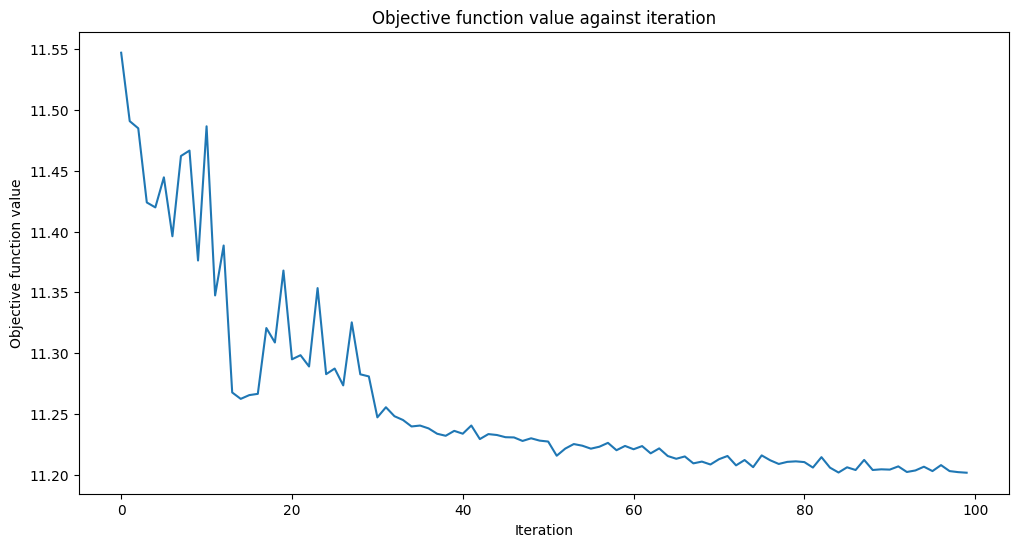

VQC trained in 115.87471652030945 seconds
Final objective-function value : 11.20171298448109


In [152]:
start = time.time()
VQC_model.fit(train_features, train_labels.to_numpy())
end = time.time()

print("VQC trained in", end - start, "seconds")
print("Final objective-function value :", VQC_model.fit_result.fun)
# print("Number of optimization cycles :", )

**1. Does the objective function decrease ?**

Yes, the objective function decreases.

**2. Is the decrease monotonic ?**

But it's not monotonic.

**3. How many iterations appear necessary to reach a stable value ?**

It appears that we need more than 60 iterations for the value to be stable.

In [153]:
train_mean_accuracy = VQC_model.score(train_features, train_labels)
test_mean_accuracy = VQC_model.score(test_features, test_labels)

print("Train mean accuracy :", train_mean_accuracy)
print("Test mean accuracy :", test_mean_accuracy)

Train mean accuracy : 0.65
Test mean accuracy : 0.6333333333333333


**1. Does the VQC generalize well ?**

The accuracy is pretty low.

**2. Which model (SVC or VQC) performs better on the training set ?**

SVC performs better on the training set (0.99 vs 0.65).

**3. Which model (SVC or VQC) performs better on the test set ?**

SVC performs better on the test set (0.967 vs 0.633).

**4. Is the difference between SVC and VQC significant ?**

The difference is really significant between the 2 models.


### Part VI - Investigating the ansatz

In [154]:
efficient_ansatz = efficient_su2(num_qubits=4, reps=3)

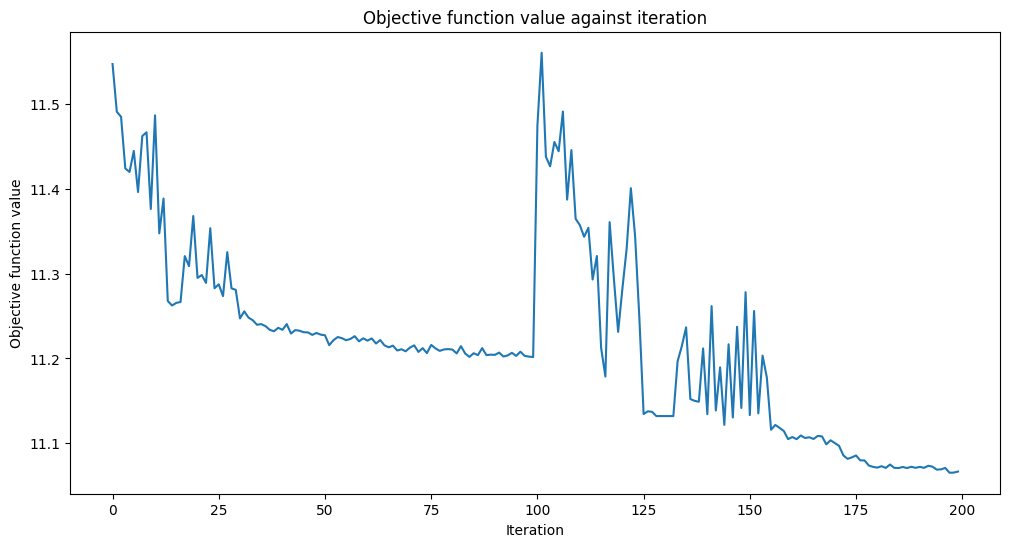

VQC trained in 121.3212902545929 seconds
Final objective-function value : 11.065357690082493


In [155]:
VQC_model = VQC(num_qubits=4, feature_map=feature_map, ansatz=efficient_ansatz, optimizer=optimizer, sampler=StatevectorSampler(seed=SEED), callback=callback_graph)

start = time.time()
VQC_model.fit(train_features, train_labels.to_numpy())
end = time.time()

print("VQC trained in", end - start, "seconds")
print("Final objective-function value :", VQC_model.fit_result.fun)

In [156]:
train_mean_accuracy = VQC_model.score(train_features, train_labels)
test_mean_accuracy = VQC_model.score(test_features, test_labels)

print("Train mean accuracy :", train_mean_accuracy)
print("Test mean accuracy :", test_mean_accuracy)

Train mean accuracy : 0.675
Test mean accuracy : 0.6333333333333333


**1. Which ansatz performs best ?**

After several runs, the 2 ansatz performs approximately the same.

**2. Which one converge faster ?**

The first ansatz (RealAmplitude) converge faster in this case.
